# ETF Pair Research

This notebook studies 12 candidate ETF pairs using a single
504-session formation window ending on December 31, 2014.

The analysis covers integration diagnostics, OLS hedge ratios,
Engle–Granger tests, Holm correction, and within-group selection.

All model estimates and selection decisions use formation data only.
No strategy returns are calculated.

In [1]:
from pathlib import Path
from itertools import combinations
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import statsmodels
import statsmodels.api as sm

from statsmodels.tsa.stattools import adfuller, coint
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.sm_exceptions import CollinearityWarning
from IPython.display import display


ROOT = Path.cwd().resolve()

if not (ROOT / "configs" / "base.yaml").exists():
    ROOT = ROOT.parent

if not (ROOT / "configs" / "base.yaml").exists():
    raise FileNotFoundError("Project configuration not found.")

RESULTS_DIR = ROOT / "results" / "week2"
FIGURES_DIR = RESULTS_DIR / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(ROOT)
print("statsmodels:", statsmodels.__version__)

/Users/puppixx1610/Projects/pairs-trading-research
statsmodels: 0.15.0


In [2]:
with (ROOT / "configs" / "base.yaml").open() as file:
    config = yaml.safe_load(file)

groups = config["groups"]

tickers = sorted(
    ticker
    for members in groups.values()
    for ticker in members
)

formation_sessions = config["strategy"]["formation_sessions"]
significance_level = config["selection"]["significance_level"]
correction = config["selection"]["correction"]
max_pairs_per_group = config["selection"]["max_pairs_per_group"]

prices = pd.read_parquet(
    ROOT / "data" / "processed" / "adjusted_close_development.parquet"
)

prices = prices.loc[:, tickers].sort_index()

assert prices.index.is_unique
assert prices.index.is_monotonic_increasing
assert prices.index.max() < pd.Timestamp("2020-01-01")
assert formation_sessions == 504
assert correction == "holm"
assert max_pairs_per_group == 1

display(prices.head())

ticker,EEM,EFA,IEMG,ITOT,IVV,SCHB,SCHF,SPY,VEA,VOO,VTI,VWO
Date,,,,,,,,,,,,
2010-01-04,30.194559,34.581207,NaN,18.998682,84.413353,3.375323,8.490403,84.368996,21.372812,NaN,42.853348,27.168003
2010-01-05,30.413719,34.611679,NaN,19.058338,84.658447,3.386658,8.522492,84.592285,21.384987,NaN,43.017845,27.257706
2010-01-06,30.477345,34.757996,NaN,19.084444,84.725273,3.389175,8.535327,84.651871,21.391077,NaN,43.077679,27.424297
2010-01-07,30.300598,34.623890,NaN,19.151566,85.096657,3.400511,8.483987,85.009201,21.348471,NaN,43.257130,27.187220
2010-01-08,30.540976,34.898182,NaN,19.222418,85.386330,3.410586,8.573833,85.292084,21.579727,NaN,43.399216,27.353817


In [3]:
FORMATION_END = pd.Timestamp("2014-12-31")

MAX_LAG = 12
AUTOLAG = "aic"
ADF_REGRESSION = "c"
COINT_TREND = "c"

formation = prices.loc[:FORMATION_END].tail(formation_sessions)

assert len(formation) == formation_sessions
assert formation.index.max() == FORMATION_END
assert formation.notna().all().all()
assert np.isfinite(formation.to_numpy()).all()
assert formation.gt(0).all().all()

print("Formation start:", formation.index.min().date())
print("Formation end:", formation.index.max().date())
print("Observations:", len(formation))

Formation start: 2013-01-02
Formation end: 2014-12-31
Observations: 504


In [4]:
log_prices = np.log(formation)

diagnostic_rows = []

for ticker in tickers:
    level = log_prices[ticker]
    difference = level.diff().dropna()

    level_test = adfuller(
        level,
        maxlag=MAX_LAG,
        regression=ADF_REGRESSION,
        autolag=AUTOLAG,
    )

    difference_test = adfuller(
        difference,
        maxlag=MAX_LAG,
        regression=ADF_REGRESSION,
        autolag=AUTOLAG,
    )

    diagnostic_rows.append({
        "ticker": ticker,
        "level_adf_stat": level_test[0],
        "level_adf_p": level_test[1],
        "level_lags": level_test[2],
        "difference_adf_stat": difference_test[0],
        "difference_adf_p": difference_test[1],
        "difference_lags": difference_test[2],
    })

integration = pd.DataFrame(diagnostic_rows).set_index("ticker")

integration["i1_pattern"] = (
    integration["level_adf_p"].ge(significance_level)
    & integration["difference_adf_p"].lt(significance_level)
)

display(integration.round(4))

/var/folders/vm/cf1rrn4x3pnd8tfc800w6mg80000gn/T/ipykernel_12004/3836586110.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  level_test = adfuller(
/var/folders/vm/cf1rrn4x3pnd8tfc800w6mg80000gn/T/ipykernel_12004/3836586110.py:16: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  difference_test = adfuller(
/var/folders/vm/cf1rrn4x3pnd8tfc800w6mg80000gn/T/ipykernel_12004/3

,level_adf_stat,level_adf_p,level_lags,difference_adf_stat,difference_adf_p,difference_lags,i1_pattern
ticker,,,,,,,
EEM,-2.6277,0.0874,0,-23.5346,0.0,0,True
EFA,-2.0231,0.2765,1,-23.9913,0.0,0,True
IEMG,-2.4511,0.1278,0,-23.6733,0.0,0,True
ITOT,-1.3616,0.6005,0,-23.1019,0.0,0,True
IVV,-1.3192,0.6203,0,-23.3462,0.0,0,True
SCHB,-1.4148,0.5752,0,-23.0730,0.0,0,True
SCHF,-1.8955,0.3342,2,-15.3476,0.0,1,True
SPY,-1.3023,0.6281,0,-23.4199,0.0,0,True
VEA,-2.0300,0.2736,1,-24.0935,0.0,0,True


In [5]:
def analyze_pairs(window, groups):
    rows = []

    for group, members in groups.items():
        for a, b in combinations(sorted(members), 2):
            pair = window[[a, b]]

            if pair.isna().any().any():
                raise ValueError(f"{a}-{b}: incomplete formation data")

            y = np.log(pair[a])
            x = np.log(pair[b])

            model = sm.OLS(y, sm.add_constant(x)).fit()
            alpha = float(model.params["const"])
            beta = float(model.params[b])

            spread = y - alpha - beta * x

            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always", CollinearityWarning)

                test_stat, p_value, _ = coint(
                    y,
                    x,
                    trend=COINT_TREND,
                    maxlag=MAX_LAG,
                    autolag=AUTOLAG,
                )

            warning_text = "; ".join(
                str(item.message) for item in caught
            )

            valid_test = (
                np.isfinite(test_stat)
                and np.isfinite(p_value)
                and not any(
                    issubclass(item.category, CollinearityWarning)
                    for item in caught
                )
            )

            pair_returns = pair.pct_change(fill_method=None).dropna()

            rows.append({
                "group": group,
                "A": a,
                "B": b,
                "observations": len(pair),
                "formation_start": pair.index.min(),
                "formation_end": pair.index.max(),
                "return_correlation": pair_returns[a].corr(pair_returns[b]),
                "alpha": alpha,
                "beta": beta,
                "ols_r_squared": model.rsquared,
                "spread_mean": spread.mean(),
                "spread_std": spread.std(ddof=1),
                "coint_stat": test_stat,
                "coint_p": p_value,
                "valid_test": valid_test,
                "warning": warning_text,
            })

    return pd.DataFrame(rows)

In [6]:
pair_results = analyze_pairs(formation, groups)

assert len(pair_results) == 12

display(
    pair_results[
        [
            "group",
            "A",
            "B",
            "return_correlation",
            "beta",
            "ols_r_squared",
            "spread_std",
            "coint_p",
            "valid_test",
        ]
    ].round(6)
)

warnings_found = pair_results.loc[
    pair_results["warning"].ne(""),
    ["A", "B", "warning"],
]

display(warnings_found)

,group,A,B,return_correlation,beta,ols_r_squared,spread_std,coint_p,valid_test
0,us_large_cap,IVV,SPY,0.998288,1.004200,0.999993,0.000290,0.000000,True
1,us_large_cap,IVV,VOO,0.996250,1.000890,0.999945,0.000796,0.843711,True
2,us_large_cap,SPY,VOO,0.996099,0.996698,0.999942,0.000815,0.446028,True
3,us_total_market,ITOT,SCHB,0.994857,1.002262,0.999577,0.002212,0.879685,True
4,us_total_market,ITOT,VTI,0.994777,1.000284,0.999321,0.002801,0.805451,True
5,us_total_market,SCHB,VTI,0.997337,0.998126,0.999944,0.000803,0.699464,True
6,developed_ex_us,EFA,SCHF,0.985830,1.038704,0.994841,0.004862,0.151217,True
7,developed_ex_us,EFA,VEA,0.995611,0.989344,0.999381,0.001684,0.113915,True
8,developed_ex_us,SCHF,VEA,0.985324,0.948227,0.995615,0.004305,0.065003,True
9,emerging_markets,EEM,IEMG,0.992403,1.019140,0.991277,0.004618,0.359859,True


,A,B,warning


In [7]:
# Invalid numerical tests cannot produce a rejection.
holm_input = pair_results["coint_p"].where(
    pair_results["valid_test"],
    1.0,
)

rejected, adjusted_p, _, _ = multipletests(
    holm_input.to_numpy(),
    alpha=significance_level,
    method=correction,
)

pair_results["holm_p"] = adjusted_p
pair_results["reject_no_cointegration"] = rejected

pair_results["eligible"] = (
    pair_results["valid_test"]
    & pair_results["reject_no_cointegration"]
    & pair_results["beta"].gt(0)
    & pair_results["spread_std"].gt(0)
    & np.isfinite(pair_results["spread_std"])
)

pair_results["i1_pattern_A"] = pair_results["A"].map(
    integration["i1_pattern"]
)

pair_results["i1_pattern_B"] = pair_results["B"].map(
    integration["i1_pattern"]
)

display(
    pair_results[
        [
            "group",
            "A",
            "B",
            "coint_p",
            "holm_p",
            "reject_no_cointegration",
            "eligible",
            "i1_pattern_A",
            "i1_pattern_B",
        ]
    ].round(6)
)

,group,A,B,coint_p,holm_p,reject_no_cointegration,eligible,i1_pattern_A,i1_pattern_B
0,us_large_cap,IVV,SPY,0.000000,0.000000,True,True,True,True
1,us_large_cap,IVV,VOO,0.843711,1.000000,False,False,True,True
2,us_large_cap,SPY,VOO,0.446028,1.000000,False,False,True,True
3,us_total_market,ITOT,SCHB,0.879685,1.000000,False,False,True,True
4,us_total_market,ITOT,VTI,0.805451,1.000000,False,False,True,True
5,us_total_market,SCHB,VTI,0.699464,1.000000,False,False,True,True
6,developed_ex_us,EFA,SCHF,0.151217,1.000000,False,False,True,True
7,developed_ex_us,EFA,VEA,0.113915,1.000000,False,False,True,True
8,developed_ex_us,SCHF,VEA,0.065003,0.715032,False,False,True,True
9,emerging_markets,EEM,IEMG,0.359859,1.000000,False,False,True,True


In [8]:
ranked = (
    pair_results.loc[pair_results["eligible"]]
    .sort_values(["group", "holm_p", "A", "B"])
)

selected = (
    ranked.groupby("group", sort=False)
    .head(max_pairs_per_group)
    .copy()
)

selected_index = pd.MultiIndex.from_frame(selected[["A", "B"]])
all_index = pd.MultiIndex.from_frame(pair_results[["A", "B"]])

pair_results["selected"] = all_index.isin(selected_index)

display(
    selected[
        [
            "group",
            "A",
            "B",
            "alpha",
            "beta",
            "spread_mean",
            "spread_std",
            "holm_p",
            "i1_pattern_A",
            "i1_pattern_B",
        ]
    ]
)

groups_without_selection = sorted(
    set(groups) - set(selected["group"])
)

print("Selected pairs:", len(selected))
print("Groups without selection:", groups_without_selection)

,group,A,B,alpha,beta,spread_mean,spread_std,holm_p,i1_pattern_A,i1_pattern_B
0,us_large_cap,IVV,SPY,-0.018414,1.0042,5.579135e-14,0.00029,1.274922e-25,True,True


Selected pairs: 1
Groups without selection: ['developed_ex_us', 'emerging_markets', 'us_total_market']


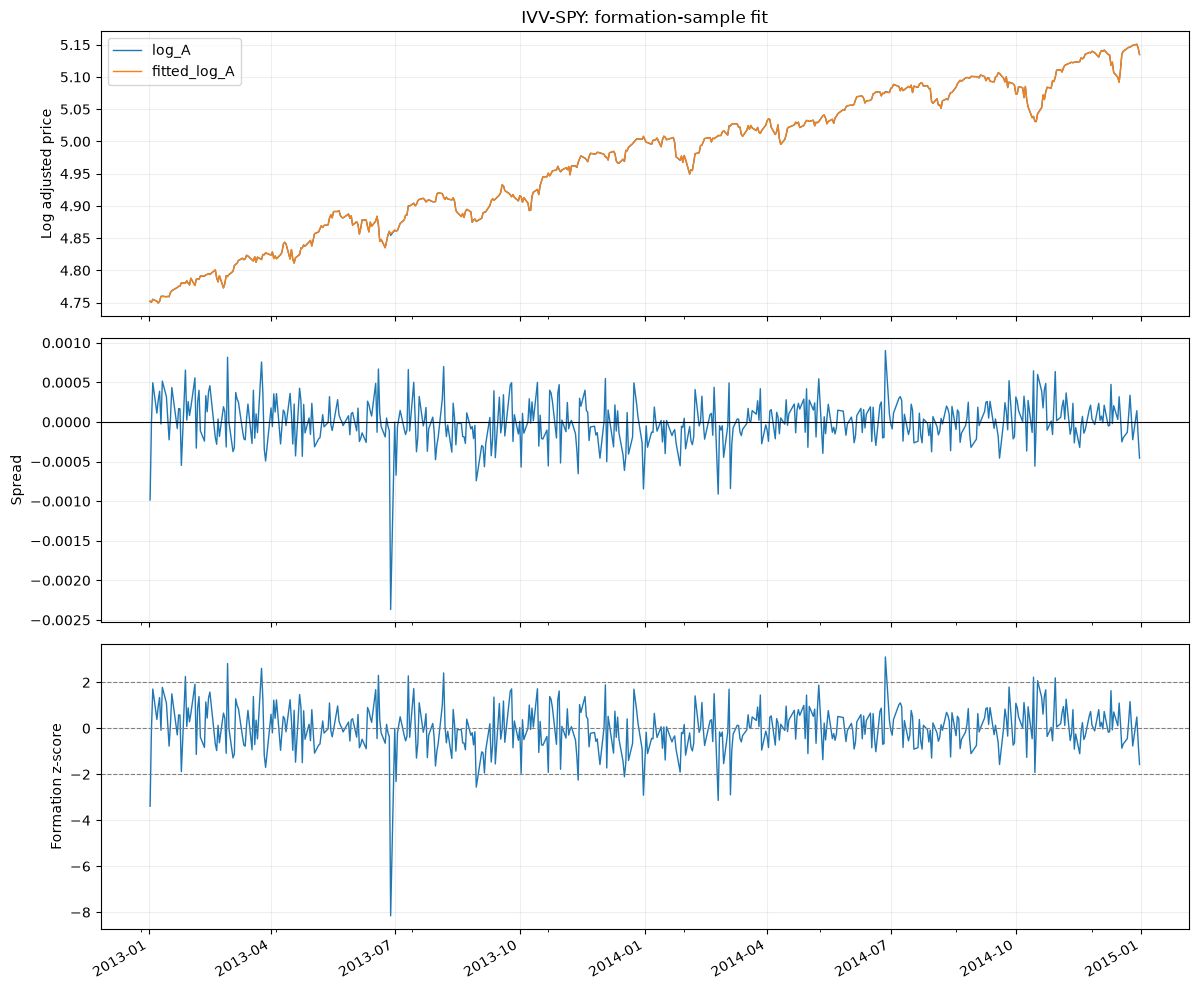

beta        1.0042
coint_p        0.0
holm_p         0.0
eligible      True
selected      True
Name: 0, dtype: object

In [9]:
A = "IVV"
B = "SPY"

example = pair_results.loc[
    pair_results["A"].eq(A)
    & pair_results["B"].eq(B)
].iloc[0]

alpha = example["alpha"]
beta = example["beta"]

y = log_prices[A]
fitted = alpha + beta * log_prices[B]

spread = y - fitted
spread_std = example["spread_std"]

if not np.isfinite(spread_std) or spread_std <= 0:
    raise ValueError("The example spread cannot be standardized.")

z_score = (
    spread - example["spread_mean"]
) / spread_std

example_spread = pd.DataFrame({
    "log_A": y,
    "fitted_log_A": fitted,
    "spread": spread,
    "z_score": z_score,
})

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

example_spread[["log_A", "fitted_log_A"]].plot(
    ax=axes[0],
    linewidth=1,
)

axes[0].set_title(f"{A}-{B}: formation-sample fit")
axes[0].set_ylabel("Log adjusted price")

spread.plot(ax=axes[1], linewidth=1)
axes[1].axhline(example["spread_mean"], color="black", linewidth=0.8)
axes[1].set_ylabel("Spread")

z_score.plot(ax=axes[2], linewidth=1)

for threshold in [-2, 0, 2]:
    axes[2].axhline(
        threshold,
        color="gray",
        linestyle="--",
        linewidth=0.8,
    )

axes[2].set_ylabel("Formation z-score")
axes[2].set_xlabel("")

for ax in axes:
    ax.grid(alpha=0.2)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "ivv_spy_formation.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

display(example[["beta", "coint_p", "holm_p", "eligible", "selected"]])

In [10]:
np.testing.assert_allclose(
    spread,
    y - alpha - beta * log_prices[B],
)

assert abs(spread.mean()) < 1e-8
assert abs(z_score.mean()) < 1e-8

np.testing.assert_allclose(
    z_score.std(ddof=1),
    1.0,
)

assert selected["group"].is_unique
assert selected["eligible"].all()
assert selected["holm_p"].lt(significance_level).all()

print("Spread calculations and selection checks passed.")

Spread calculations and selection checks passed.


In [11]:
changed_prices = prices.copy()

future_dates = changed_prices.index > FORMATION_END

multipliers = pd.Series(
    np.linspace(1.2, 2.0, len(tickers)),
    index=tickers,
)

changed_prices.loc[future_dates, tickers] = (
    changed_prices.loc[future_dates, tickers]
    .mul(multipliers, axis="columns")
)

changed_formation = (
    changed_prices.loc[:FORMATION_END]
    .tail(formation_sessions)
)

pd.testing.assert_frame_equal(
    formation,
    changed_formation,
)

rechecked = analyze_pairs(changed_formation, groups)

comparison_columns = [
    "A",
    "B",
    "alpha",
    "beta",
    "spread_mean",
    "spread_std",
    "coint_stat",
    "coint_p",
    "valid_test",
]

pd.testing.assert_frame_equal(
    pair_results[comparison_columns],
    rechecked[comparison_columns],
)

print("Changes after the formation cutoff did not affect model estimates.")

Changes after the formation cutoff did not affect model estimates.


In [12]:
summary = pd.Series({
    "Formation start": formation.index.min().date(),
    "Formation end": formation.index.max().date(),
    "Formation observations": len(formation),
    "Candidate pairs": len(pair_results),
    "Numerically valid tests": int(pair_results["valid_test"].sum()),
    "Raw p-values below 5%": int(
        (
            pair_results["valid_test"]
            & pair_results["coint_p"].lt(significance_level)
        ).sum()
    ),
    "Holm rejections": int(
        pair_results["reject_no_cointegration"].sum()
    ),
    "Eligible pairs": int(pair_results["eligible"].sum()),
    "Selected pairs": len(selected),
    "ETFs with I(1)-consistent ADF pattern": int(
        integration["i1_pattern"].sum()
    ),
})

display(summary)

diagnostic_concerns = selected.loc[
    ~(
        selected["i1_pattern_A"]
        & selected["i1_pattern_B"]
    ),
    ["group", "A", "B", "i1_pattern_A", "i1_pattern_B"],
]

print("Selected pairs requiring integration-diagnostic review:")
display(diagnostic_concerns)

Formation start                          2013-01-02
Formation end                            2014-12-31
Formation observations                          504
Candidate pairs                                  12
Numerically valid tests                          12
Raw p-values below 5%                             1
Holm rejections                                   1
Eligible pairs                                    1
Selected pairs                                    1
ETFs with I(1)-consistent ADF pattern            12
dtype: object

Selected pairs requiring integration-diagnostic review:


,group,A,B,i1_pattern_A,i1_pattern_B


In [13]:
integration.to_csv(
    RESULTS_DIR / "integration_diagnostics.csv"
)

pair_results.to_csv(
    RESULTS_DIR / "pair_research.csv",
    index=False,
)

selected.to_csv(
    RESULTS_DIR / "selected_pairs.csv",
    index=False,
)

example_spread.to_csv(
    RESULTS_DIR / "ivv_spy_formation_spread.csv"
)

summary.to_csv(
    RESULTS_DIR / "formation_summary.csv",
    header=["value"],
)

print("Saved Week 2 research outputs.")

Saved Week 2 research outputs.


In [14]:
import json

research_settings = {
    "formation_start": str(formation.index.min().date()),
    "formation_end": str(FORMATION_END.date()),
    "formation_sessions": formation_sessions,
    "max_lag": MAX_LAG,
    "autolag": AUTOLAG,
    "adf_regression": ADF_REGRESSION,
    "coint_trend": COINT_TREND,
    "significance_level": significance_level,
    "multiple_testing_method": correction,
    "max_pairs_per_group": max_pairs_per_group,
    "regression_direction": "alphabetical",
    "integration_diagnostics_used_as_filter": False,
    "statsmodels_version": statsmodels.__version__,
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
}

(RESULTS_DIR / "research_settings.json").write_text(
    json.dumps(research_settings, indent=2)
)

print("Saved research settings.")

Saved research settings.


## Findings

### Integration diagnostics

All 12 ETFs show the expected I(1)-consistent pattern at the 5% level:
the ADF tests do not reject a unit root in log prices, but reject
one in first differences.

Log-level p-values range from 0.0874 for EEM to 0.6281 for SPY.
All first-difference p-values are below 0.0001.

These results support the integration assumption used in the pair
tests under this specification. They do not prove that the series
are I(1).

### Pair tests and selection

All 12 Engle–Granger tests returned finite results, with no recorded
near-collinearity warnings.

IVV-SPY is the only pair with a raw p-value below 0.05 and the only
pair that passes Holm correction. Its raw p-value is approximately
1.06e-26 and its adjusted p-value is 1.27e-25.

| Group | Selected pair |
|---|---|
| US large-cap | IVV-SPY |
| US broad market | None |
| Developed markets outside the US | None |
| Emerging markets | None |

No additional pairs were removed by Holm correction in this window:
the other 11 pairs already had raw p-values above 0.05.

Both IVV and SPY also satisfy the reported integration diagnostic.
No selected pair has a conflicting diagnostic flag.

### Correlation is not enough

SCHB-VTI has a daily return correlation of 0.9973, but its
cointegration p-value is 0.6995. IVV-VOO also has a high return
correlation of 0.9963, yet its cointegration p-value is 0.8437.

These examples show why return correlation alone is not sufficient
for pair selection.

### IVV-SPY spread

The estimated relationship is:

log(IVV) = -0.018414 + 1.004200 × log(SPY) + spread

The formation spread has a standard deviation of approximately
0.0002903 log-price units. Its mean is close to zero, as expected
from an OLS regression with an intercept.

The small spread raises a practical question for the next stage:
will the available price movements cover execution and borrowing
costs? The statistical result alone cannot answer that.

The plotted z-score is standardized using the full formation sample.
It cannot be treated as an executable signal during 2013–2014.

### Checks and next step

The spread and z-score checks passed. Changing prices after
December 31, 2014 did not affect formation estimates or test results.

The result applies to one formation window. The next step is to
implement signals and position accounting after the formation cutoff,
then evaluate costs and whether the relationship persists.